#### Домашнее задание ad-hoc аналитика

##### Контекст
20 июля на Android кликабельность top_search резко выше обычной. Что это: ошибка трекинга, и тогда чиним логирование, или реальный эффект, и тогда решаем, менять ли формат показа на Android.

##### Проблема
20 июля на Android наблюдается резкий рост кликабельности блока top_search. Пока непонятно, отражает ли он реальные действия пользователей или возник из-за некорректной регистрации событий клика. От причины зависит дальнейшие действия: исправляем логирования или провереряем  формат.

##### 7 вопросов до SQL
1. Цель:
хотим понять, чем вызван скачок на Android 20 июля, и на этой основе решить, нужно ли менять формат показа.
2. Гипотеза:
всплеск кликабельности top_search на Android 20 июля связан со сбоем в логировании кликов, а не с реальным изменением интереса пользователей к формату.
3. Метрика:
основная метрика: CTR (показатель кликабельности) = показы, у которых есть клик / все показы. также посмотрим, какая доля кликов дошла до отклика и как часто показ привел к целевому действию (показы с откликом/все показы).
4. Период:
1–28 июля 2026, отдельно 20 июля (это целевой день, когда был обнаружен скачок) и остальные дни после появления top_boost (с 15 июля, без 20 числа).
5. Сегменты:
платформа Android и top_search; другие платформы и top_search и top_boost на Android.
6. Критерий успеха:
проверяем, насколько CTR 20 июля отличается от базового CTR с учётом 95% доверительных интервалов Уилсона (выявление аномалии). также оцениваем, сопровождается ли рост кликов ростом конверсии в отклик.
7. Решение:
при ошибке логирования: исправить и пересчитать метрики;
если клики корректны, проверить изменение формата в A/B-тесте;
если данных недостаточно, то пока не менять показ до доплнительной проверки.

##### Глубина: разбор
Ошибка может привести к ненужному изменению интерфейса или оставить неисправное логирование, поэтому одной быстрой цифры недостаточно, цена ошибки средняя. Формат можно отключить, поэтому технически изменение обратимо, но перед раскаткой все равно нужно проверить логи и воронку.

##### Подготовка данных

In [11]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import duckdb
from plotly.subplots import make_subplots
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

DATA = Path("data")

con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")

def sql(query: str) -> pd.DataFrame:
    return con.execute(query).df()

impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv


##### Функции для работы (из лекции)

In [12]:
from typing import Iterable, Optional, Sequence, Tuple


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates: pd.Series, cutoff: str, before="before", after="after") -> pd.Series:
    # Размечает даты на период до и после точки cutoff.
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


print("Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager")


Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager


##### Качество данных

Необходимо выполнить проверку данных перед началом работы: проверка размера таблиц, дублей, пропусков, уникальности id, связей между событиями. Также сверяем дату, платформу и продукт и связанных показа, клика и отклика.

In [13]:
tables = {"impressions": impressions, "clicks": clicks, "responses": responses}
key_by_table = {
    "impressions": ["impression_id"],
    "clicks": ["click_id"],
    "responses": ["response_id"],
}

for name, df in tables.items():
    print(f"\nтаблица: {name}")
    display(summarize_dq(df, key_cols=key_by_table[name]))

# проверка связи событий: каждый клик должен ссылаться на показ, каждый отклик на клик + проверяем повторы клика на одном показе
click_link = clicks.merge(
    impressions[["impression_id", "event_date", "platform", "product"]],
    on="impression_id", how="left", suffixes=("_click", "_impression"), indicator=True,
)
response_link = responses.merge(
    clicks[["click_id", "event_date", "platform", "product"]],
    on="click_id", how="left", suffixes=("_response", "_click"), indicator=True,
)

click_matched = click_link[click_link["_merge"] == "both"]
response_matched = response_link[response_link["_merge"] == "both"]
click_mismatch = sum((click_matched[f"{col}_click"] != click_matched[f"{col}_impression"]).sum() for col in ["event_date", "platform", "product"])
response_mismatch = sum((response_matched[f"{col}_response"] != response_matched[f"{col}_click"]).sum() for col in ["event_date", "platform", "product"])

link_checks = pd.DataFrame([
    ["клики без показа", int((click_link["_merge"] == "left_only").sum())],
    ["повторные клики на один показ", int(clicks.duplicated("impression_id").sum())],
    ["несовпадения даты/платформы/продукта: клик и показ", int(click_mismatch)],
    ["отклики без клика", int((response_link["_merge"] == "left_only").sum())],
    ["повторные отклики на один клик", int(responses.duplicated("click_id").sum())],
    ["несовпадения даты/платформы/продукта: отклик и клик", int(response_mismatch)],
], columns=["проверка связи", "найдено"])
display(link_checks)


таблица: impressions


,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0



таблица: clicks


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0



таблица: responses


,проверка,значение
0,строк всего,421
1,полных дублей строк,0
2,пропуски: response_id,0
3,пропуски: click_id,0
4,пропуски: impression_id,0
5,пропуски: event_date,0
6,пропуски: platform,0
7,пропуски: segment,0
8,пропуски: product,0
9,пропуски: vacancy_id,0


,проверка связи,найдено
0,клики без показа,0
1,повторные клики на один показ,0
2,несовпадения даты/платформы/продукта: клик и п...,0
3,отклики без клика,0
4,повторные отклики на один клик,0
5,несовпадения даты/платформы/продукта: отклик и...,0


В таблицах показов, кликов и откликов не обнаружено пропусков и повторов по ключам. Все клики связаны с показами, все отклики с кликами; даты, платформы и продукты связанных событий совпадают. 
Это подтверждает структурную согласованность таблиц, но не исключает возможную ошибку: ложное событие клика тоже может иметь уникальный id и ссылаться на существующий показ. 

##### SQL-расчет воронки по дням

Считаем число уникальных показов, число показов, по которым зафиксирован хотя бы один клик, и число показов, по которым зафиксирован отклик.

In [14]:
q_daily = """
WITH clicked AS (
    SELECT DISTINCT impression_id
    FROM clicks
    WHERE impression_id IS NOT NULL
),
responded AS (
    SELECT DISTINCT impression_id
    FROM responses
    WHERE impression_id IS NOT NULL
)
SELECT
    i.event_date,
    i.platform,
    i.product,
    COUNT(DISTINCT i.impression_id) AS impressions,
    COUNT(DISTINCT c.impression_id) AS clicked_impressions,
    COUNT(DISTINCT r.impression_id) AS responded_impressions
FROM impressions AS i
LEFT JOIN clicked AS c
    ON c.impression_id = i.impression_id
LEFT JOIN responded AS r
    ON r.impression_id = i.impression_id
GROUP BY 1, 2, 3
ORDER BY 1, 2, 3
"""

# Выполняем запрос и приводим даты к типу pandas datetime.
daily = sql(q_daily)
daily["event_date"] = pd.to_datetime(daily["event_date"])

# Основная метрика и дополнительные показатели воронки.
daily["ctr"] = (
    daily["clicked_impressions"] / daily["impressions"]
)
daily["launch_period"] = period_flag(
    daily["event_date"],
    "2026-07-15",
    before="до запуска",
    after="после запуска",
)
daily["click_to_response"] = (
    daily["responded_impressions"]
    / daily["clicked_impressions"].replace(0, np.nan)
)
daily["impression_to_response"] = (
    daily["responded_impressions"] / daily["impressions"]
)

day = pd.Timestamp("2026-07-20")

focus = daily[
    (daily["platform"] == "ANDROID")
    & (daily["product"] == "top_search")
].copy()

all_top_search = daily[
    daily["product"] == "top_search"
].copy()

focus_ci = proportion_table(
    focus.assign(
        successes=focus["clicked_impressions"],
        n=focus["impressions"],
    ),
    group_cols=["event_date"],
    success_col="successes",
    n_col="n",
    rate_name="ctr",
)

display(
    focus.sort_values("event_date")[
        [
            "event_date",
            "launch_period",
            "impressions",
            "clicked_impressions",
            "ctr",
            "responded_impressions",
            "click_to_response",
            "impression_to_response",
        ]
    ].style.format(
        {
            "ctr": "{:.1%}",
            "click_to_response": "{:.1%}",
            "impression_to_response": "{:.2%}",
        },
        na_rep="—",
    )
)

,event_date,launch_period,impressions,clicked_impressions,ctr,responded_impressions,click_to_response,impression_to_response
0,2026-07-01 00:00:00,до запуска,599,16,2.7%,3,18.8%,0.50%
4,2026-07-02 00:00:00,до запуска,623,21,3.4%,3,14.3%,0.48%
8,2026-07-03 00:00:00,до запуска,683,29,4.2%,3,10.3%,0.44%
12,2026-07-04 00:00:00,до запуска,595,22,3.7%,1,4.5%,0.17%
16,2026-07-05 00:00:00,до запуска,666,21,3.2%,3,14.3%,0.45%
20,2026-07-06 00:00:00,до запуска,670,15,2.2%,1,6.7%,0.15%
24,2026-07-07 00:00:00,до запуска,644,14,2.2%,3,21.4%,0.47%
28,2026-07-08 00:00:00,до запуска,645,20,3.1%,5,25.0%,0.78%
32,2026-07-09 00:00:00,до запуска,598,26,4.3%,4,15.4%,0.67%
36,2026-07-10 00:00:00,до запуска,657,22,3.3%,2,9.1%,0.30%


По полученной таблице видно, что 20 июля на Android у top_search наблюдается заметный скачок CTR по сравнению с остальными днями (значение 0.094). 
Базой для решения, расположенного ниже будут дни после запуска top_boost (после 15 июля) и без целевого дня (20 июля).

##### Сравнения по сегментам

Сравним целевой день с базой после запуска top_boost, затем посмотрим Android / top_boost и top_search на остальных платформах.

In [15]:
def aggregate_rate(frame: pd.DataFrame) -> dict:
    n = int(frame["impressions"].sum())
    successes = int(frame["clicked_impressions"].sum())
    return {
        "показы": n,
        "показы с кликом": successes,
        "CTR": successes / n if n else np.nan,
    }

post_base = daily[
    (daily["launch_period"] == "после запуска")
    & (daily["event_date"] != day)
]

focus_day = focus.loc[focus["event_date"] == day]
focus_base = post_base[
    (post_base["platform"] == "ANDROID")
    & (post_base["product"] == "top_search")
]

comparison_rows = []
for label, frame in [
    ("top_search / Android / 20 июля", focus_day),
    ("top_search / Android / база после запуска", focus_base),
]:
    row = aggregate_rate(frame)
    row["срез"] = label
    comparison_rows.append(row)

boost_day = daily[
    (daily["platform"] == "ANDROID")
    & (daily["product"] == "top_boost")
    & (daily["event_date"] == day)
]
boost_base = post_base[
    (post_base["platform"] == "ANDROID")
    & (post_base["product"] == "top_boost")
]
for label, frame in [
    ("top_boost / Android / 20 июля", boost_day),
    ("top_boost / Android / база после запуска", boost_base),
]:
    row = aggregate_rate(frame)
    row["срез"] = label
    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)[["срез", "показы", "показы с кликом", "CTR"]]
display(comparison.style.format({"CTR": "{:.1%}"}))

platform_rows = []
for platform in sorted(daily["platform"].dropna().unique()):
    d = daily[
        (daily["platform"] == platform)
        & (daily["product"] == "top_search")
        & (daily["event_date"] == day)
    ]
    b = post_base[
        (post_base["platform"] == platform)
        & (post_base["product"] == "top_search")
    ]
    d_rate = aggregate_rate(d)
    b_rate = aggregate_rate(b)
    platform_rows.append({
        "платформа": platform,
        "показы 20 июля": d_rate["показы"],
        "CTR 20 июля": d_rate["CTR"],
        "показы в базе": b_rate["показы"],
        "CTR базы": b_rate["CTR"],
    })
platform_comparison = pd.DataFrame(platform_rows)
display(platform_comparison.style.format({"CTR 20 июля": "{:.1%}", "CTR базы": "{:.1%}"}))

target_stats = aggregate_rate(focus_day)
base_stats = aggregate_rate(focus_base)
boost_target_stats = aggregate_rate(boost_day)
boost_base_stats = aggregate_rate(boost_base)

,срез,показы,показы с кликом,CTR
0,top_search / Android / 20 июля,383,36,9.4%
1,top_search / Android / база после запуска,4990,147,2.9%
2,top_boost / Android / 20 июля,252,29,11.5%
3,top_boost / Android / база после запуска,3073,136,4.4%


,платформа,показы 20 июля,CTR 20 июля,показы в базе,CTR базы
0,ANDROID,383,9.4%,4990,2.9%
1,DESKTOP_WEB,714,6.6%,8546,5.4%
2,IOS,293,3.1%,4239,3.4%
3,MOBILE_WEB,406,7.9%,4972,4.9%


Сравнение показывает, что 20 июля CTR повышен не только у Android/top_search (9.4%). Похожий сигнал есть у Android/top_boost (11.5%) и top_search на mobile web (7.9%).
Это основание для проверки механизма регистрации клика и изменения трафика или интерфейса. По агрегированным данным нельзя доказать общую ошибку трекинга.

##### CTR с доверительным интервалом

In [16]:
import plotly.graph_objects as go

focus_july = focus_ci[
    focus_ci["event_date"].between(
        pd.Timestamp("2026-07-01"),
        pd.Timestamp("2026-07-28"),
    )
].sort_values("event_date").copy()

day = pd.Timestamp("2026-07-20")

regular_days = focus_july[focus_july["event_date"] != day]
target_day = focus_july[focus_july["event_date"] == day].iloc[0]

baseline_days = focus_july[
    (focus_july["event_date"] >= pd.Timestamp("2026-07-15"))
    & (focus_july["event_date"] != day)
]

baseline = proportion_table(
    baseline_days.assign(period="база"),
    group_cols=["period"],
    success_col="successes",
    n_col="n",
    rate_name="ctr",
).iloc[0]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=regular_days["event_date"],
    y=regular_days["ctr"],
    mode="markers",
    marker=dict(color="#7B9CCB", size=8),
    error_y=dict(
        type="data",
        array=regular_days["ci_high"] - regular_days["ctr"],
        arrayminus=regular_days["ctr"] - regular_days["ci_low"],
        color="#AAB4C3",
        thickness=1,
        width=3,
    ),
    hovertemplate="%{x|%d.%m.%Y}<br>CTR: %{y:.1%}<extra></extra>",
    showlegend=False,
))

fig.add_trace(go.Scatter(
    x=[target_day["event_date"]],
    y=[target_day["ctr"]],
    mode="markers",
    marker=dict(color="#D9534F", size=11),
    error_y=dict(
        type="data",
        array=[target_day["ci_high"] - target_day["ctr"]],
        arrayminus=[target_day["ctr"] - target_day["ci_low"]],
        color="#D9534F",
        thickness=1.5,
        width=3,
    ),
    hovertemplate="%{x|%d.%m.%Y}<br>CTR: %{y:.1%}<extra></extra>",
    showlegend=False,
))

fig.add_hrect(
    y0=baseline["ci_low"],
    y1=baseline["ci_high"],
    fillcolor="#E39A45",
    opacity=0.15,
    line_width=0,
    layer="below",
)

fig.add_hline(
    y=baseline["ctr"],
    line_dash="dash",
    line_color="#E39A45",
    line_width=2
)

fig.update_layout(
    title="CTR top_search на Android — июль 2026",
    xaxis_title="дата",
    yaxis_title="CTR",
    yaxis_tickformat=".0%",
    height=500,
    template="plotly_white",
    showlegend=False,
    margin=dict(l=65, r=35, t=65, b=75),
)

tick_dates = pd.to_datetime([
    "2026-07-01", "2026-07-05", "2026-07-10",
    "2026-07-15", "2026-07-20", "2026-07-25",
])

fig.update_xaxes(
    tickmode="array",
    tickvals=tick_dates,
    ticktext=["1 июл", "5 июл", "10 июл", "15 июл", "20 июл", "25 июл"],
    showgrid=False,
)

fig.update_yaxes(
    showgrid=True,
    gridcolor="#EAEAEA",
    rangemode="tozero",
)

fig.show()

print(f"20 июля: CTR {target_day['ctr']:.1%}")
print(f"95% ДИ: {target_day['ci_low']:.1%}–{target_day['ci_high']:.1%}")
print(f"база 15–28 июля без 20 июля: CTR {baseline['ctr']:.1%}")
print(f"95% ДИ: {baseline['ci_low']:.1%}–{baseline['ci_high']:.1%}")


20 июля: CTR 9.4%
95% ДИ: 6.9%–12.7%
база 15–28 июля без 20 июля: CTR 2.9%
95% ДИ: 2.5%–3.5%


На графике видно, что CTR 20 июля заметно выше значений остальных дней после запуска top_boost (CTR = 9,4% (36/383), база составляет 2,9% (147/4 990)). Интервал Уилсона для целевого дня не пересекается с интервалом объединенной базы.

##### Распределение дневного CTR по платформам

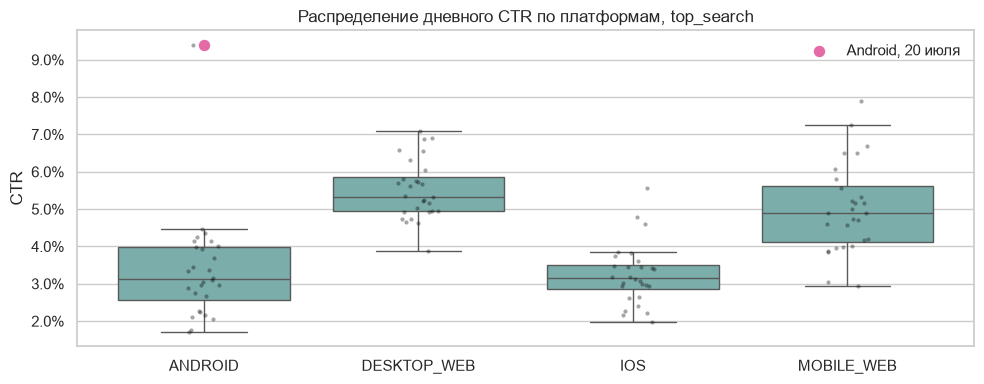

In [17]:
platform_order = sorted(all_top_search["platform"].dropna().unique())

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=all_top_search,
    x="platform",
    y="ctr",
    order=platform_order,
    ax=ax,
    color="#72B7B2",
    showfliers=False,
)

sns.stripplot(
    data=all_top_search,
    x="platform",
    y="ctr",
    order=platform_order,
    ax=ax,
    color="black",
    size=3,
    alpha=0.35,
)

android_jul20 = all_top_search[
    (all_top_search["platform"] == "ANDROID")
    & (all_top_search["event_date"] == day)
]

if not android_jul20.empty:
    android_x = platform_order.index("ANDROID")
    ax.scatter(
        android_x,
        android_jul20["ctr"].iloc[0],
        color="#E56BA6",
        marker="o",
        s=85,
        edgecolor="white",
        linewidth=1,
        zorder=5,
        label="Android, 20 июля",
    )
    ax.legend(frameon=False)

ax.set_title("Распределение дневного CTR по платформам, top_search")
ax.set_ylabel("CTR")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))

plt.tight_layout()
plt.show()

Распределение дневного CTR показывает, что 20 июля Android находится заметно выше типичного диапазона значений по платформе. При этом в целевой день повышенный CTR наблюдается и на Mobile Web.

##### Проверка всей воронки

Сравниваем две дополнительные метрики: конверсию из клика в отклик и конверсию из показа в отклик. Для обеих долей рассчитываем 95% интервал Уилсона.

In [18]:
focus_daily = daily[
    (daily["platform"] == "ANDROID")
    & (daily["product"] == "top_search")
]
focus_day_response = focus_daily[focus_daily["event_date"] == day]
focus_base_response = focus_daily[
    (focus_daily["launch_period"] == "после запуска")
    & (focus_daily["event_date"] != day)
]

def funnel_row(label, frame):
    n = int(frame["impressions"].sum())
    clicked = int(frame["clicked_impressions"].sum())
    responded = int(frame["responded_impressions"].sum())
    ctr = clicked / n if n else np.nan
    click_to_response = responded / clicked if clicked else np.nan
    impression_to_response = responded / n if n else np.nan
    ctr_ci = wilson_ci(clicked, n)
    click_to_response_ci = wilson_ci(responded, clicked)
    impression_to_response_ci = wilson_ci(responded, n)
    return {
        "срез": label,
        "показы": n,
        "показы с кликом": clicked,
        "показы с откликом": responded,
        "CTR": ctr,
        "95% ДИ CTR": f"{ctr_ci[0]:.1%}–{ctr_ci[1]:.1%}",
        "отклики / клики": click_to_response,
        "95% ДИ отклики / клики": f"{click_to_response_ci[0]:.1%}–{click_to_response_ci[1]:.1%}",
        "отклики / показы": impression_to_response,
        "95% ДИ отклики / показы": f"{impression_to_response_ci[0]:.2%}–{impression_to_response_ci[1]:.2%}",
    }

funnel_comparison = pd.DataFrame([
    funnel_row("20 июля", focus_day_response),
    funnel_row("База после запуска без 20 июля", focus_base_response),
])

display(funnel_comparison.style.format({
    "CTR": "{:.1%}",
    "отклики / клики": "{:.1%}",
    "отклики / показы": "{:.2%}",
}))

response_day_click_ci = wilson_ci(
    int(focus_day_response["responded_impressions"].sum()),
    int(focus_day_response["clicked_impressions"].sum()),
)
response_base_click_ci = wilson_ci(
    int(focus_base_response["responded_impressions"].sum()),
    int(focus_base_response["clicked_impressions"].sum()),
)
response_day_impression_ci = wilson_ci(
    int(focus_day_response["responded_impressions"].sum()),
    int(focus_day_response["impressions"].sum()),
)
response_base_impression_ci = wilson_ci(
    int(focus_base_response["responded_impressions"].sum()),
    int(focus_base_response["impressions"].sum()),
)

,срез,показы,показы с кликом,показы с откликом,CTR,95% ДИ CTR,отклики / клики,95% ДИ отклики / клики,отклики / показы,95% ДИ отклики / показы
0,20 июля,383,36,4,9.4%,6.9%–12.7%,11.1%,4.4%–25.3%,1.04%,0.41%–2.65%
1,База после запуска без 20 июля,4990,147,22,2.9%,2.5%–3.5%,15.0%,10.1%–21.6%,0.44%,0.29%–0.67%


20 июля конверсия из клика в отклик составила 11.1%, что ниже базового значения 15%. Однако доверительные интервалы пересекаются, в целевой группе зафиксировано всего четыре отклика, поэтому имеющихся данных недостаточно, чтобы сказать, что качество кликов изменилось.
Доля показов с откликом составила 1.04% против 0.44% в базе, но доверительные интервалы также пересекаются. Увеличение CTR пока нельзя интерпретировать как доказательство повышения эффективности рекламного блока.

##### Интерпретация и действие

Решение: пока не менять формат показа top_seach на Android. Необходима проверка логирования за 20 июля.
CTR 20 июля составляет 9,4% (36 показов с кликом из 383) против 2,9% (147 из 4 990) в базе после запуска top_boost. Похожий рост наблюдается у top_boost на Android и у top_search на Mobile Web (возможен общий фактор). 
Отклик получили 4 из 36 кликнувших показов в целевой день (11,1%) и 22 из 147 в базе (15%). Вывод о качестве кликов сделать нельзя. 
Следующие действия:
Проверить исходные логи за 20 июля на Android и Mobile Web; сопоставить зарегистрированные события с фактическими действиями пользователей и проверить изменения версии приложения, интерфейса и размещения блока. Если логирование корректно, проверить изменение формата в A/B-тесте. 

Ограничения: невозможно подтвердить, что каждый зарегистрированный клик был вызван реальным действием пользователя. Также не были проверены версии приложения, изменения интерфейса, позиции рекламного блока и механизм отправки события 20 июля. 

Как итог, аномалия CTR подтверждена, но ее причина не установлена. Проверка откликов не дает надежного подтверждения ни улучшения, ни ухудшения качества кликов. На текущем этапе корректное действие: проверить логирование и не менять формат до получения дополнительных доказательств.

In [19]:
platform_summary = "; ".join(
    f"{row['платформа']}: {row['CTR 20 июля']:.1%} "
    f"против {row['CTR базы']:.1%} в базе"
    for _, row in platform_comparison.iterrows()
)

target_ctr_ci = wilson_ci(
    int(target_stats["показы с кликом"]),
    int(target_stats["показы"]),
)
base_ctr_ci = wilson_ci(
    int(base_stats["показы с кликом"]),
    int(base_stats["показы"]),
)

response_day_row = funnel_comparison.iloc[0]
response_base_row = funnel_comparison.iloc[1]

extra_result = (
    f" Воронка до отклика: 20 июля отклик был у "
    f"{int(response_day_row['показы с откликом'])} показов "
    f"из {int(response_day_row['показы с кликом'])} показов с кликом "
    f"({response_day_row['отклики / клики']:.1%}); "
    f"в базе у {int(response_base_row['показы с откликом'])} "
    f"из {int(response_base_row['показы с кликом'])} "
    f"({response_base_row['отклики / клики']:.1%}). "
    f"95% ДИ конверсии из клика в отклик: "
    f"{response_day_click_ci[0]:.1%}–{response_day_click_ci[1]:.1%} "
    f"и {response_base_click_ci[0]:.1%}–{response_base_click_ci[1]:.1%}; "
    "интервалы пересекаются."
)

one_pager_text = one_pager(
    decision=(
        "Не менять формат top_search на Android до проверки механизма логирования."
    ),

    context=(
        "20 июля 2026 года обнаружен резкий рост CTR top_search на Android."
    ),

    what_done=(
        "Проверены пропуски, полные дубли, уникальность ключей и связи показов, кликов и откликов. "
        "Отдельно проверено аномальное значение CTR 20 июля относительно базы после запуска top_boost. "
        "Сопоставлены показатели других платформ и формата top_boost, рассчитаны доверительные интервалы, построены графики дневной динамики и распределения CTR."
    ),

    result=(
        f"CTR Android/top_search 20 июля составил "
        f"{target_stats['CTR']:.1%} "
        f"({target_stats['показы с кликом']} из "
        f"{target_stats['показы']} показов) против "
        f"{base_stats['CTR']:.1%} "
        f"({base_stats['показы с кликом']} из "
        f"{base_stats['показы']}) в базе после запуска top_boost. "
        f"95% ДИ: {target_ctr_ci[0]:.1%}–{target_ctr_ci[1]:.1%} "
        f"и {base_ctr_ci[0]:.1%}–{base_ctr_ci[1]:.1%}; интервалы не пересекаются. "
        f"Сравнение top_search по платформам: {platform_summary}. "
        f"Дополнительно CTR Android/top_boost составил "
        f"{boost_target_stats['CTR']:.1%} против "
        f"{boost_base_stats['CTR']:.1%} в базе."
        + extra_result
    ),

    limits=(
        "Проверки не выявили ошибок в связях между событиями, но не позволяют подтвердить, что каждый зарегистрированный клик соответствует реальному действию пользователя. "
        "В целевой группе всего четыре показа с откликом. "
        "Не проверены исходные клиентские логи, версии приложения, изменения интерфейса и расположения блока. "
    ),

    action=(
        "Проверить события клика за 20 июля на Android и Mobile Web и возможные изменения приложения и интерфейса. "
        "Если логирование корректно, при необходимости роверить изменение формата в A/B-тесте. "
        "До получения дополнительных доказательств формат не менять."
    ),
)

print(one_pager_text)

Path("one_pager.txt").write_text(
    one_pager_text,
    encoding="utf-8",
)

ИТОГОВАЯ СПРАВКА

Решение:
Не менять формат top_search на Android до проверки механизма логирования.

Контекст:
20 июля 2026 года обнаружен резкий рост CTR top_search на Android.

Что сделали:
Проверены пропуски, полные дубли, уникальность ключей и связи показов, кликов и откликов. Отдельно проверено аномальное значение CTR 20 июля относительно базы после запуска top_boost. Сопоставлены показатели других платформ и формата top_boost, рассчитаны доверительные интервалы, построены графики дневной динамики и распределения CTR.

Результат:
CTR Android/top_search 20 июля составил 9.4% (36 из 383 показов) против 2.9% (147 из 4990) в базе после запуска top_boost. 95% ДИ: 6.9%–12.7% и 2.5%–3.5%; интервалы не пересекаются. Сравнение top_search по платформам: ANDROID: 9.4% против 2.9% в базе; DESKTOP_WEB: 6.6% против 5.4% в базе; IOS: 3.1% против 3.4% в базе; MOBILE_WEB: 7.9% против 4.9% в базе. Дополнительно CTR Android/top_boost составил 11.5% против 4.4% в базе. Воронка до отклика: 20 июля от

1957